In [2]:
# Step 4.1: Load dataset and split into training and testing sets

import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split

# Define categorical variables
categorical_cols = [
    'State',
    'Strata',
    'Sex',
    'Ethnic_Group',
    'Citizenship',
    'Marital_Status',
    'Educational_Attainment',
    'Highest_Certificate_Obtained',
    'Field_of_Study',
    'Occupation_2D',
    'Industry_2D'
]

# Load dataset
data_path = Path("../data/fulldata.csv")

if not data_path.exists():
    data_path = Path("data/fulldata.csv")

df = pd.read_csv(
    data_path,
    dtype={col: 'string' for col in categorical_cols}
)

# Define target variable
target = 'G14_Total_salaries_and_wages_includes_overtime'

# Define variables that should not be used for prediction
exclude_cols = [
    target,
    'G8_Total_salaries_and_wages',
    'Weight',
    'Citizenship'
]

# Separate features and target
X = df.drop(columns=exclude_cols)
y = df[target]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Display results
print("Training Set:", X_train.shape)
print("Testing Set:", X_test.shape)

print("\nTarget Variable:", target)

print("\nInput Features:")
print(X.columns.tolist())

Training Set: (21940, 11)
Testing Set: (5485, 11)

Target Variable: G14_Total_salaries_and_wages_includes_overtime

Input Features:
['State', 'Strata', 'Sex', 'Age', 'Ethnic_Group', 'Marital_Status', 'Educational_Attainment', 'Highest_Certificate_Obtained', 'Field_of_Study', 'Occupation_2D', 'Industry_2D']


In [3]:
# Step 4.2: Data Preprocessing

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Identify categorical and numerical features
cat_features = [
    col for col in categorical_cols
    if col in X_train.columns
]

num_features = ['Age']

# Create copies of training and testing data
X_train_clean = X_train.copy()
X_test_clean = X_test.copy()

# Handle missing categorical values
for col in cat_features:
    X_train_clean[col] = (
        X_train_clean[col]
        .fillna('Missing_or_Not_Recorded')
        .astype(str)
    )

    X_test_clean[col] = (
        X_test_clean[col]
        .fillna('Missing_or_Not_Recorded')
        .astype(str)
    )

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=True
)

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', categorical_transformer, cat_features),
        ('num', numerical_transformer, num_features)
    ]
)

# Fit preprocessing on training data only
X_train_processed = preprocessor.fit_transform(X_train_clean)

# Apply the same preprocessing to testing data
X_test_processed = preprocessor.transform(X_test_clean)

# Display results
print("Original Training Shape:", X_train.shape)
print("Processed Training Shape:", X_train_processed.shape)

print("\nOriginal Testing Shape:", X_test.shape)
print("Processed Testing Shape:", X_test_processed.shape)

print("\nPreprocessing completed successfully!")

Original Training Shape: (21940, 11)
Processed Training Shape: (21940, 188)

Original Testing Shape: (5485, 11)
Processed Testing Shape: (5485, 188)

Preprocessing completed successfully!


In [4]:
# Step 5.1: Decision Tree Regression

import numpy as np

from sklearn.tree import DecisionTreeRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Initialize the model
dt_model = DecisionTreeRegressor(
    max_depth=10,
    min_samples_leaf=10,
    random_state=42
)

# 2. Train the model
dt_model.fit(X_train_processed, y_train)

# 3. Make predictions
y_train_pred = dt_model.predict(X_train_processed)
y_test_pred = dt_model.predict(X_test_processed)

# 4. Evaluate the model
def evaluate_model(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    return mae, rmse, r2

train_mae, train_rmse, train_r2 = evaluate_model(
    y_train, y_train_pred
)

test_mae, test_rmse, test_r2 = evaluate_model(
    y_test, y_test_pred
)

# 5. Display results
print("Decision Tree Regression Results")

print("\nTraining Performance:")
print("MAE:", round(train_mae, 2))
print("RMSE:", round(train_rmse, 2))
print("R²:", round(train_r2, 4))

print("\nTesting Performance:")
print("MAE:", round(test_mae, 2))
print("RMSE:", round(test_rmse, 2))
print("R²:", round(test_r2, 4))

Decision Tree Regression Results

Training Performance:
MAE: 874.92
RMSE: 1597.06
R²: 0.5861

Testing Performance:
MAE: 932.05
RMSE: 1603.41
R²: 0.5375


In [5]:
# Step 5.2: Random Forest Regression

from sklearn.ensemble import RandomForestRegressor

# 1. Initialize Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

# 2. Train the model
rf_model.fit(X_train_processed, y_train)

# 3. Make predictions
rf_train_pred = rf_model.predict(X_train_processed)
rf_test_pred = rf_model.predict(X_test_processed)

# 4. Evaluate training performance
rf_train_mae, rf_train_rmse, rf_train_r2 = evaluate_model(
    y_train,
    rf_train_pred
)

# 5. Evaluate testing performance
rf_test_mae, rf_test_rmse, rf_test_r2 = evaluate_model(
    y_test,
    rf_test_pred
)

# 6. Display results
print("Random Forest Regression Results")

print("\nTraining Performance:")
print("MAE:", round(rf_train_mae, 2))
print("RMSE:", round(rf_train_rmse, 2))
print("R²:", round(rf_train_r2, 4))

print("\nTesting Performance:")
print("MAE:", round(rf_test_mae, 2))
print("RMSE:", round(rf_test_rmse, 2))
print("R²:", round(rf_test_r2, 4))

Random Forest Regression Results

Training Performance:
MAE: 840.29
RMSE: 1565.83
R²: 0.6022

Testing Performance:
MAE: 881.66
RMSE: 1528.83
R²: 0.5795


In [6]:
# Step 5.3: Compare Decision Tree and Random Forest

comparison = pd.DataFrame({
    'Model': [
        'Decision Tree',
        'Random Forest'
    ],
    'MAE': [
        test_mae,
        rf_test_mae
    ],
    'RMSE': [
        test_rmse,
        rf_test_rmse
    ],
    'R2': [
        test_r2,
        rf_test_r2
    ]
})

display(comparison.round(4))

,Model,MAE,RMSE,R2
0,Decision Tree,932.0465,1603.4084,0.5375
1,Random Forest,881.6590,1528.8272,0.5795


In [7]:
# Step 5.4: Support Vector Regression (LinearSVR)

from sklearn.svm import LinearSVR
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler

# 1. Initialize LinearSVR
svr_model = TransformedTargetRegressor(
    regressor=LinearSVR(
        C=1.0,
        epsilon=0.0,
        loss='squared_epsilon_insensitive',
        dual=False,
        max_iter=5000,
        random_state=42
    ),
    transformer=StandardScaler()
)

# 2. Train the model
svr_model.fit(X_train_processed, y_train)

# 3. Make predictions
svr_train_pred = svr_model.predict(X_train_processed)
svr_test_pred = svr_model.predict(X_test_processed)

# 4. Evaluate training performance
svr_train_mae, svr_train_rmse, svr_train_r2 = evaluate_model(
    y_train,
    svr_train_pred
)

# 5. Evaluate testing performance
svr_test_mae, svr_test_rmse, svr_test_r2 = evaluate_model(
    y_test,
    svr_test_pred
)

# 6. Display results
print("LinearSVR Regression Results")

print("\nTraining Performance:")
print("MAE:", round(svr_train_mae, 2))
print("RMSE:", round(svr_train_rmse, 2))
print("R²:", round(svr_train_r2, 4))

print("\nTesting Performance:")
print("MAE:", round(svr_test_mae, 2))
print("RMSE:", round(svr_test_rmse, 2))
print("R²:", round(svr_test_r2, 4))

LinearSVR Regression Results

Training Performance:
MAE: 918.4
RMSE: 1654.24
R²: 0.556

Testing Performance:
MAE: 917.91
RMSE: 1533.65
R²: 0.5768


In [8]:
# Step 5.4: XGBoost Regression

from xgboost import XGBRegressor

# 1. Initialize XGBoost model
xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='reg:squarederror',
    tree_method='hist',
    random_state=42,
    n_jobs=-1
)

# 2. Train the model
xgb_model.fit(X_train_processed, y_train)

# 3. Make predictions
xgb_train_pred = xgb_model.predict(X_train_processed)
xgb_test_pred = xgb_model.predict(X_test_processed)

# 4. Evaluate training performance
xgb_train_mae, xgb_train_rmse, xgb_train_r2 = evaluate_model(
    y_train, xgb_train_pred
)

# 5. Evaluate testing performance
xgb_test_mae, xgb_test_rmse, xgb_test_r2 = evaluate_model(
    y_test, xgb_test_pred
)

# 6. Display results
print("XGBoost Regression Results")

print("\nTraining Performance:")
print("MAE:", round(xgb_train_mae, 2))
print("RMSE:", round(xgb_train_rmse, 2))
print("R²:", round(xgb_train_r2, 4))

print("\nTesting Performance:")
print("MAE:", round(xgb_test_mae, 2))
print("RMSE:", round(xgb_test_rmse, 2))
print("R²:", round(xgb_test_r2, 4))

XGBoost Regression Results

Training Performance:
MAE: 688.03
RMSE: 1134.58
R²: 0.7911

Testing Performance:
MAE: 802.92
RMSE: 1488.46
R²: 0.6014


In [9]:
# Step 5.5: AdaBoost Regression

from sklearn.ensemble import AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor

# Initialize AdaBoost model
ada_model = AdaBoostRegressor(
    estimator=DecisionTreeRegressor(
        max_depth=4,
        min_samples_leaf=10,
        random_state=42
    ),
    n_estimators=100,
    learning_rate=0.05,
    random_state=42
)

# Train model
ada_model.fit(X_train_processed, y_train)

# Make predictions
ada_train_pred = ada_model.predict(X_train_processed)
ada_test_pred = ada_model.predict(X_test_processed)

# Evaluate performance
ada_train_mae, ada_train_rmse, ada_train_r2 = evaluate_model(
    y_train, ada_train_pred
)

ada_test_mae, ada_test_rmse, ada_test_r2 = evaluate_model(
    y_test, ada_test_pred
)

# Display results
print("AdaBoost Regression Results")

print("\nTraining Performance:")
print("MAE:", round(ada_train_mae, 2))
print("RMSE:", round(ada_train_rmse, 2))
print("R²:", round(ada_train_r2, 4))

print("\nTesting Performance:")
print("MAE:", round(ada_test_mae, 2))
print("RMSE:", round(ada_test_rmse, 2))
print("R²:", round(ada_test_r2, 4))

AdaBoost Regression Results

Training Performance:
MAE: 1170.97
RMSE: 1730.25
R²: 0.5142

Testing Performance:
MAE: 1181.35
RMSE: 1890.12
R²: 0.3573


In [10]:
# Step 5.6: Final ML Model Comparison

import pandas as pd
from pathlib import Path

# Collect testing performance
final_comparison = pd.DataFrame({
    'Model': [
        'Decision Tree',
        'Random Forest',
        'LinearSVR',
        'XGBoost',
        'AdaBoost'
    ],

    'MAE': [
        test_mae,
        rf_test_mae,
        svr_test_mae,
        xgb_test_mae,
        ada_test_mae
    ],

    'RMSE': [
        test_rmse,
        rf_test_rmse,
        svr_test_rmse,
        xgb_test_rmse,
        ada_test_rmse
    ],

    'R2': [
        test_r2,
        rf_test_r2,
        svr_test_r2,
        xgb_test_r2,
        ada_test_r2
    ]
})

# Sort by RMSE (lower is better)
final_comparison = final_comparison.sort_values(
    by='RMSE'
).reset_index(drop=True)

# Display table
display(final_comparison.round(4))

# Save results to CSV
results_path = (
    Path("../results")
    if Path("../data/fulldata.csv").exists()
    else Path("results")
)

results_path.mkdir(parents=True, exist_ok=True)

final_comparison.to_csv(
    results_path / "ML_Model_Comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

,Model,MAE,RMSE,R2
0,XGBoost,802.9178,1488.4631,0.6014
1,Random Forest,881.6590,1528.8272,0.5795
2,LinearSVR,917.9055,1533.6490,0.5768
3,Decision Tree,932.0465,1603.4084,0.5375
4,AdaBoost,1181.3463,1890.1237,0.3573


Model comparison saved successfully!


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP values calculated successfully!
SHAP shape: (300, 188)


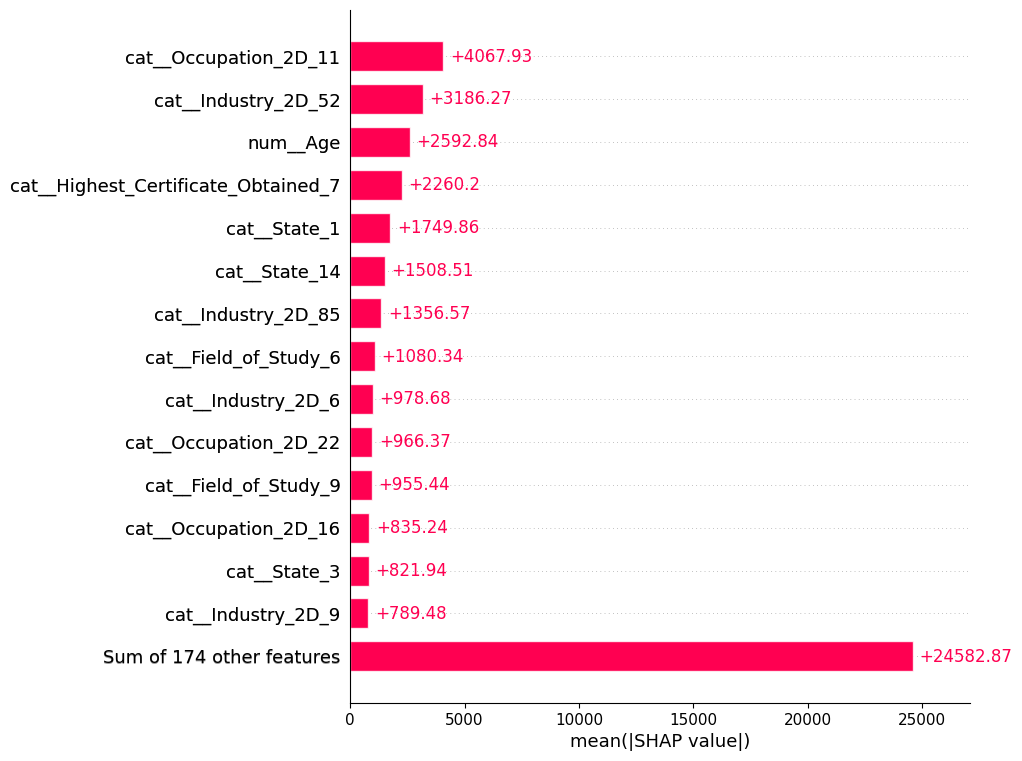

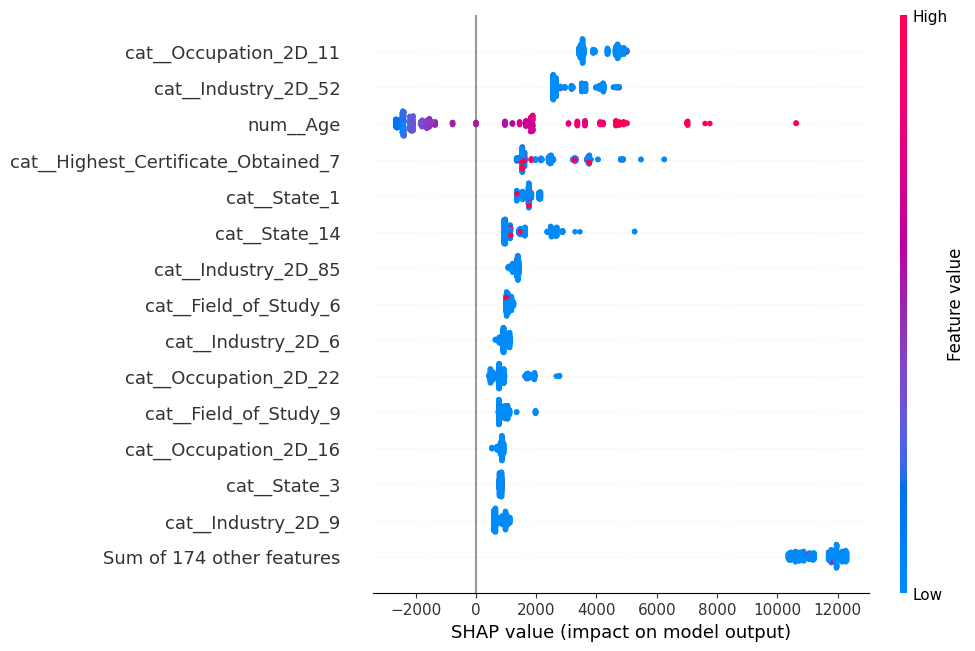

In [13]:
# Step 6.1: SHAP Analysis for XGBoost

import shap
import numpy as np
import matplotlib.pyplot as plt

# 1. Get encoded feature names
feature_names = preprocessor.get_feature_names_out()

# 2. Select 300 observations from the test set
X_shap = X_test_processed[:300]

# Convert sparse matrix to dense array
if hasattr(X_shap, "toarray"):
    X_shap = X_shap.toarray()

# 3. Create SHAP explainer
explainer = shap.TreeExplainer(xgb_model)

# 4. Calculate SHAP values
shap_values = explainer(X_shap)

# 5. Assign feature names
shap_values.feature_names = list(feature_names)

print("SHAP values calculated successfully!")
print("SHAP shape:", shap_values.values.shape)

# 6. SHAP Feature Importance
shap.plots.bar(shap_values, max_display=15)

# 7. SHAP Summary Plot
shap.plots.beeswarm(shap_values, max_display=15)

,Mean_Absolute_SHAP
Occupation_2D,11148.629883
Industry_2D,8619.799805
State,4432.850098
Highest_Certificate_Obtained,3213.229980
Age,2592.840088
Field_of_Study,2396.510010
Ethnic_Group,929.479980
Marital_Status,695.929993
Sex,363.980011
Educational_Attainment,95.809998


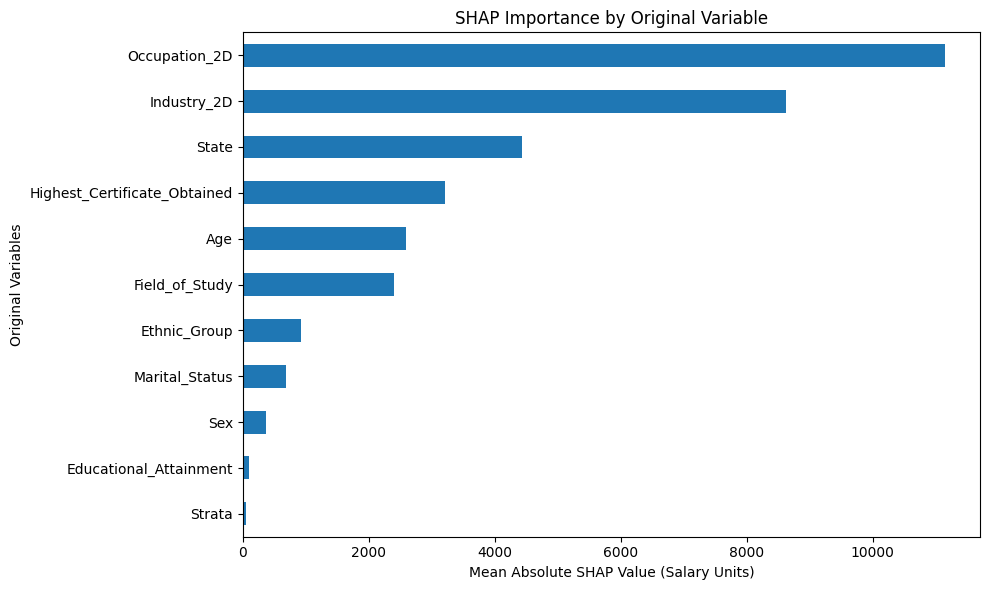

Grouped SHAP analysis completed!


In [14]:
# Step 6.2: Group SHAP values by original variables

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Get fitted One-Hot Encoder
encoder = preprocessor.named_transformers_['cat']

# Group SHAP values
grouped_shap = {}
start = 0

# Categorical variables
for variable, categories in zip(
    cat_features, encoder.categories_
):
    n = len(categories)

    grouped_shap[variable] = (
        shap_values.values[:, start:start+n].sum(axis=1)
    )

    start += n

# Numerical variables
for variable in num_features:
    grouped_shap[variable] = shap_values.values[:, start]
    start += 1

# Verify all 188 features were included
assert start == shap_values.values.shape[1]

# Calculate mean absolute grouped SHAP values
grouped_df = pd.DataFrame(grouped_shap)

importance = (
    grouped_df.abs()
    .mean()
    .sort_values(ascending=False)
    .to_frame(name='Mean_Absolute_SHAP')
)

display(importance.round(2))

# Plot original feature importance
plt.figure(figsize=(10, 6))

importance.sort_values(
    'Mean_Absolute_SHAP'
)['Mean_Absolute_SHAP'].plot(kind='barh')

plt.title('SHAP Importance by Original Variable')
plt.xlabel('Mean Absolute SHAP Value (Salary Units)')
plt.ylabel('Original Variables')
plt.tight_layout()
plt.show()

# Save results
results_path = Path("../results") if Path(
    "../data/fulldata.csv"
).exists() else Path("results")

results_path.mkdir(parents=True, exist_ok=True)

importance.to_csv(
    results_path / "SHAP_Original_Feature_Importance.csv"
)

print("Grouped SHAP analysis completed!")

In [15]:
# Step 6.3: Verify SHAP Additivity

import numpy as np

# Original model predictions
predictions = xgb_model.predict(
    X_test_processed[:300]
)

# Reconstruct predictions using SHAP
reconstructed = (
    np.asarray(shap_values.base_values).reshape(-1)
    + shap_values.values.sum(axis=1)
)

# Check reconstruction difference
max_error = np.max(
    np.abs(predictions - reconstructed)
)

print("Mean Prediction:", round(predictions.mean(), 2))
print("Mean Actual Salary:", round(y_test.iloc[:300].mean(), 2))
print("Max SHAP Reconstruction Error:", round(max_error, 6))

# Check grouping consistency
grouping_error = np.max(
    np.abs(
        grouped_df.sum(axis=1).to_numpy()
        - shap_values.values.sum(axis=1)
    )
)

print("Max Grouping Error:", round(grouping_error, 6))

Mean Prediction: 3174.89
Mean Actual Salary: 3192.78
Max SHAP Reconstruction Error: 54157.344
Max Grouping Error: 0.003906


In [16]:
# Diagnose SHAP prediction mismatch

import numpy as np

# Same 300 observations, two representations
X_sparse = X_test_processed[:300]
X_dense = X_sparse.toarray()

# XGBoost predictions
pred_sparse = xgb_model.predict(X_sparse)
pred_dense = xgb_model.predict(X_dense)

# Existing SHAP reconstruction
shap_reconstructed = (
    np.asarray(shap_values.base_values).reshape(-1)
    + shap_values.values.sum(axis=1)
)

print(
    "Sparse vs Dense Prediction Difference:",
    np.max(np.abs(pred_sparse - pred_dense))
)

print(
    "SHAP Error vs Sparse Predictions:",
    np.max(np.abs(shap_reconstructed - pred_sparse))
)

print(
    "SHAP Error vs Dense Predictions:",
    np.max(np.abs(shap_reconstructed - pred_dense))
)

Sparse vs Dense Prediction Difference: 54157.355
SHAP Error vs Sparse Predictions: 54157.344
SHAP Error vs Dense Predictions: 0.01953125


In [17]:
# Step 6.4: Correct SHAP Analysis Using Sparse Matrix

import numpy as np
import xgboost as xgb

# 1. Use the original sparse test data
X_shap_sparse = X_test_processed[:300]

# 2. Create XGBoost DMatrix
dtest_shap = xgb.DMatrix(X_shap_sparse)

# 3. Calculate SHAP contributions using XGBoost
booster = xgb_model.get_booster()

shap_contribs = booster.predict(
    dtest_shap,
    pred_contribs=True
)

# 4. Separate feature contributions and base values
corrected_shap_values = shap_contribs[:, :-1]
corrected_base_values = shap_contribs[:, -1]

# 5. Reconstruct predictions
reconstructed = (
    corrected_base_values
    + corrected_shap_values.sum(axis=1)
)

# 6. Compare against original model predictions
original_predictions = xgb_model.predict(
    X_shap_sparse
)

max_error = np.max(
    np.abs(original_predictions - reconstructed)
)

print("Corrected SHAP Shape:", corrected_shap_values.shape)

print("Original Mean Prediction:",
      round(original_predictions.mean(), 2))

print("SHAP Reconstructed Mean:",
      round(reconstructed.mean(), 2))

print("Maximum Reconstruction Error:",
      round(max_error, 6))

print(
    "SHAP Verification:",
    "PASSED" if np.allclose(
        original_predictions,
        reconstructed,
        rtol=1e-5,
        atol=0.1
    ) else "FAILED"
)

Corrected SHAP Shape: (300, 188)
Original Mean Prediction: 3174.89
SHAP Reconstructed Mean: 3174.89
Maximum Reconstruction Error: 0.015625
SHAP Verification: PASSED


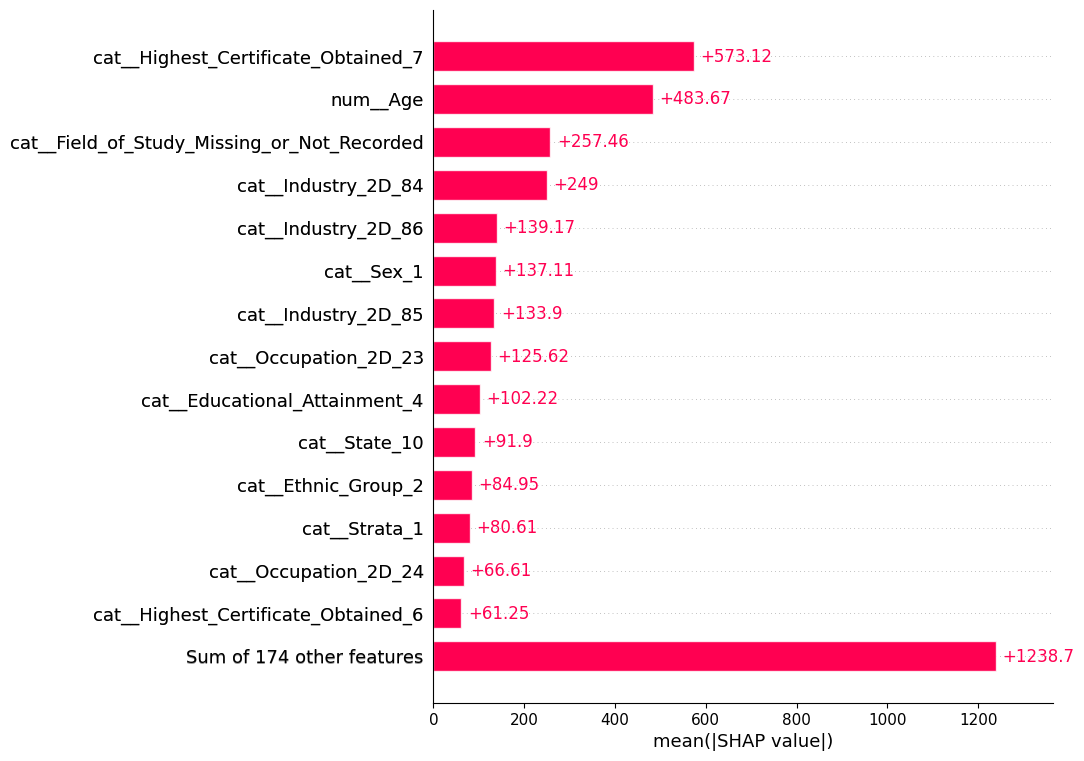

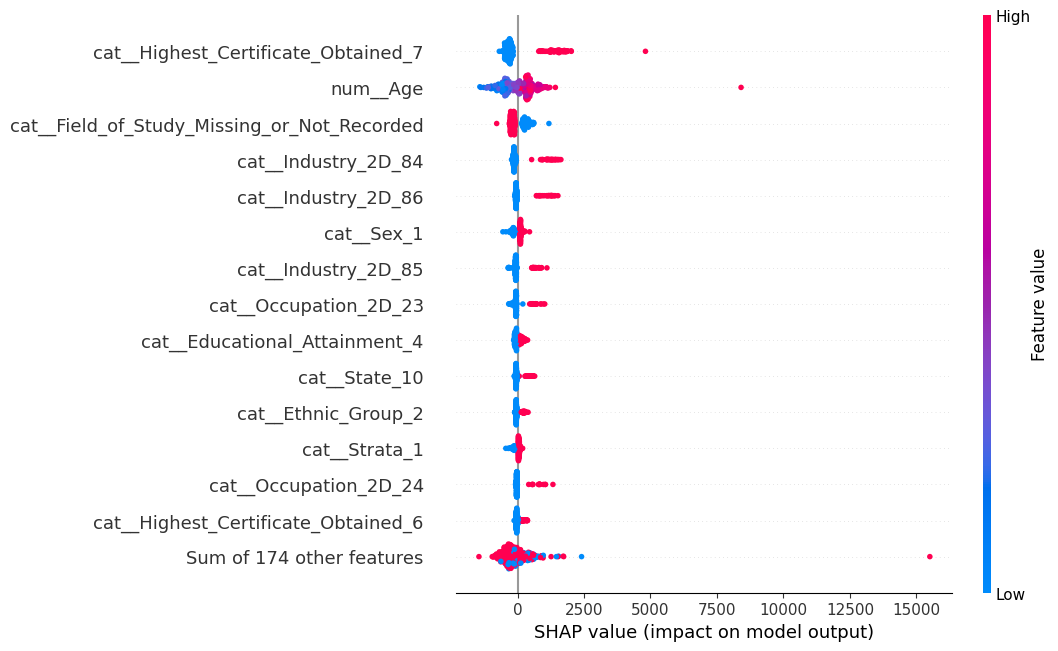

Corrected SHAP plots generated successfully!


In [18]:
# Step 6.5: Corrected SHAP Visualizations

import shap
import numpy as np
import matplotlib.pyplot as plt

# Get feature names
feature_names = list(
    preprocessor.get_feature_names_out()
)

# Create corrected SHAP Explanation
# Dense conversion is only for displaying feature values
corrected_explanation = shap.Explanation(
    values=corrected_shap_values,
    base_values=corrected_base_values,
    data=X_shap_sparse.toarray(),
    feature_names=feature_names
)

# 1. Corrected SHAP Bar Plot
shap.plots.bar(
    corrected_explanation,
    max_display=15
)

# 2. Corrected SHAP Beeswarm Plot
shap.plots.beeswarm(
    corrected_explanation,
    max_display=15
)

print("Corrected SHAP plots generated successfully!")

Maximum Grouping Error: 0.001953125

Corrected Original Variable Importance:


,Mean_Absolute_SHAP
Highest_Certificate_Obtained,575.789978
Industry_2D,531.020020
Age,483.670013
Occupation_2D,370.250000
Field_of_Study,257.480011
State,185.559998
Sex,162.850006
Ethnic_Group,140.160004
Strata,109.809998
Educational_Attainment,102.309998


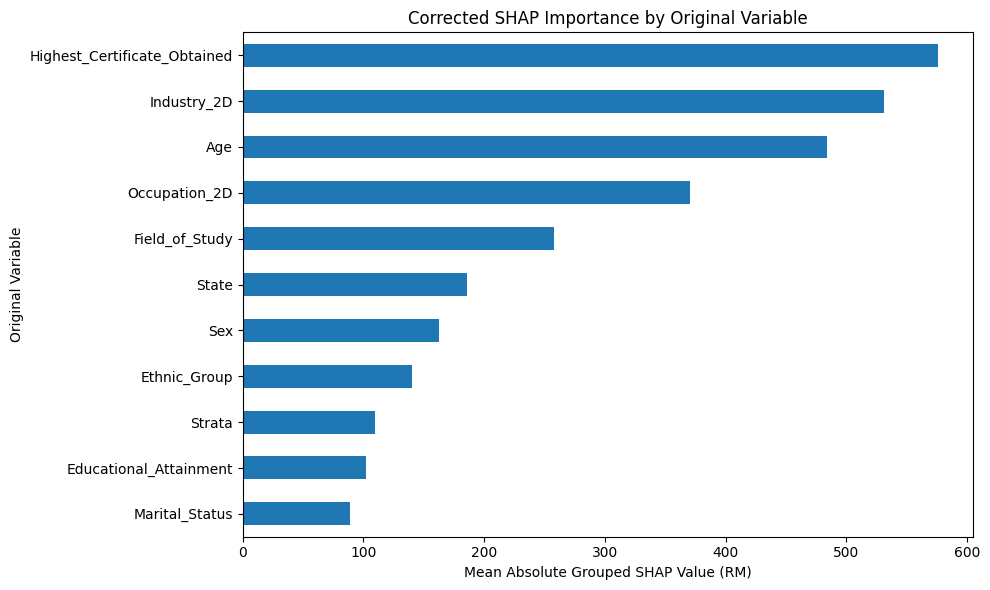

Corrected grouped SHAP analysis completed!


In [19]:
# Step 6.6: Corrected Original Variable SHAP Importance

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Get fitted One-Hot Encoder
encoder = preprocessor.named_transformers_['cat']

# 2. Group corrected SHAP values
grouped_shap = {}
start = 0

# Categorical variables
for variable, categories in zip(
    cat_features, encoder.categories_
):
    n = len(categories)

    grouped_shap[variable] = (
        corrected_shap_values[:, start:start+n].sum(axis=1)
    )

    start += n

# Numerical variables
for variable in num_features:
    grouped_shap[variable] = corrected_shap_values[:, start]
    start += 1

# 3. Verify grouping
assert start == corrected_shap_values.shape[1]

grouped_df_corrected = pd.DataFrame(grouped_shap)

grouping_error = np.max(
    np.abs(
        grouped_df_corrected.sum(axis=1).to_numpy()
        - corrected_shap_values.sum(axis=1)
    )
)

print("Maximum Grouping Error:", grouping_error)

# 4. Calculate grouped importance
corrected_importance = (
    grouped_df_corrected.abs()
    .mean()
    .sort_values(ascending=False)
    .to_frame(name='Mean_Absolute_SHAP')
)

print("\nCorrected Original Variable Importance:")
display(corrected_importance.round(2))

# 5. Plot importance
plt.figure(figsize=(10, 6))

corrected_importance.iloc[::-1][
    'Mean_Absolute_SHAP'
].plot(kind='barh')

plt.title("Corrected SHAP Importance by Original Variable")
plt.xlabel("Mean Absolute Grouped SHAP Value (RM)")
plt.ylabel("Original Variable")

plt.tight_layout()

# 6. Save results
results_path = (
    Path("../results")
    if Path("../data/fulldata.csv").exists()
    else Path("results")
)

results_path.mkdir(parents=True, exist_ok=True)

plt.savefig(
    results_path / "Corrected_SHAP_Importance.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

corrected_importance.to_csv(
    results_path / "SHAP_Original_Feature_Importance.csv"
)

print("Corrected grouped SHAP analysis completed!")